In [1]:
import pandas as pd

df = pd.read_csv("data/superstore_sales.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

In [3]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)

print("First order:", df["Order Date"].min())
print("Last order:", df["Order Date"].max())

First order: 2015-01-03 00:00:00
Last order: 2018-12-30 00:00:00


In [4]:
(df["Ship Date"] < df["Order Date"]).sum()

np.int64(0)

In [5]:
print("Duplicate rows:", df.duplicated().sum())
df[df["Postal Code"].isna()][["City", "State"]].drop_duplicates()

Duplicate rows: 0


,City,State
2234,Burlington,Vermont


In [6]:
snapshot = df["Order Date"].max() + pd.Timedelta(days=1)
snapshot

Timestamp('2018-12-31 00:00:00')

In [7]:
rfm = df.groupby("Customer ID").agg(
    LastOrder=("Order Date", "max"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
)

rfm["Recency"] = (snapshot - rfm["LastOrder"]).dt.days

print(rfm.shape)
rfm.head()

(793, 4)


,LastOrder,Frequency,Monetary,Recency
Customer ID,,,,
AA-10315,2018-06-29,5,5563.560,185
AA-10375,2018-12-11,9,1056.390,20
AA-10480,2018-04-15,4,1790.512,260
AA-10645,2018-11-05,6,5086.935,56
AB-10015,2017-11-10,3,886.156,416


In [8]:
old_way = df.groupby("Customer ID")["Order ID"].count()
print("Old average frequency (counting rows):", round(old_way.mean(), 2))
print("New average frequency (unique orders):", round(rfm["Frequency"].mean(), 2))
print("Total revenue:", round(rfm["Monetary"].sum(), 2))

Old average frequency (counting rows): 12.36
New average frequency (unique orders): 6.21
Total revenue: 2261536.78


In [9]:
rfm[["Recency", "Frequency", "Monetary"]].describe().round(1)

,Recency,Frequency,Monetary
count,793.0,793.0,793.0
mean,149.3,6.2,2851.9
std,187.1,2.5,2620.7
min,1.0,1.0,4.8
25%,31.0,4.0,1081.5
50%,76.0,6.0,2215.0
75%,185.0,8.0,3670.3
max,1166.0,17.0,25043.0


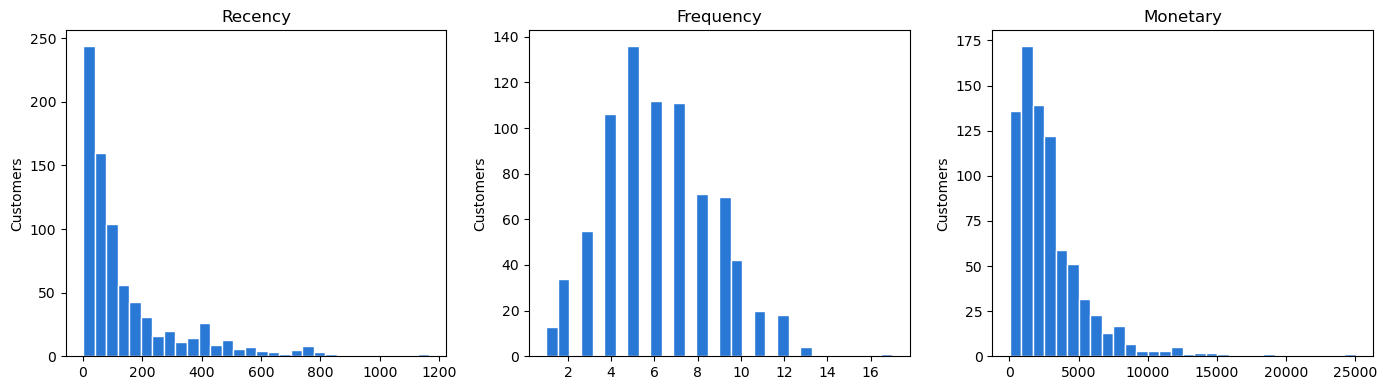

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    ax.hist(rfm[col], bins=30, color="#2a78d6", edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("Customers")

plt.tight_layout()
plt.show()

In [11]:
rfm[["Recency", "Frequency", "Monetary"]].skew().round(2)

Recency      2.23
Frequency    0.39
Monetary     2.51
dtype: float64

In [12]:
total = rfm["Monetary"].sum()
cutoff = rfm["Monetary"].quantile(0.75)
top = rfm[rfm["Monetary"] >= cutoff]

print("Top 25% spend cutoff: $", round(cutoff))
print("Customers in top 25%:", len(top))
print("Their share of revenue:", round(top["Monetary"].sum() / total * 100, 1), "%")

Top 25% spend cutoff: $ 3670
Customers in top 25%: 199
Their share of revenue: 55.5 %


In [13]:
for days in [30, 90, 180, 365]:
    share = (rfm["Recency"] <= days).mean() * 100
    print(f"Bought in the last {days} days: {share:.0f}% of customers")

Bought in the last 30 days: 24% of customers
Bought in the last 90 days: 54% of customers
Bought in the last 180 days: 74% of customers
Bought in the last 365 days: 87% of customers


In [14]:
rfm["R"] = pd.cut(rfm["Recency"], bins=[0, 90, 365, float("inf")], labels=["H", "M", "L"])
rfm["F"] = pd.cut(rfm["Frequency"], bins=[0, 4, 7, float("inf")], labels=["L", "M", "H"])

m_low = rfm["Monetary"].quantile(0.25)
m_high = rfm["Monetary"].quantile(0.75)
rfm["M"] = pd.cut(rfm["Monetary"], bins=[0, m_low, m_high, float("inf")],
                  labels=["L", "M", "H"], right=False)

rfm.head()

,LastOrder,Frequency,Monetary,Recency,R,F,M
Customer ID,,,,,,,
AA-10315,2018-06-29,5,5563.560,185,M,M,H
AA-10375,2018-12-11,9,1056.390,20,H,H,L
AA-10480,2018-04-15,4,1790.512,260,M,L,M
AA-10645,2018-11-05,6,5086.935,56,H,M,H
AB-10015,2017-11-10,3,886.156,416,L,L,L


In [15]:
for col in ["R", "F", "M"]:
    print(col, rfm[col].value_counts().reindex(["H", "M", "L"]).to_dict())

R {'H': 432, 'M': 258, 'L': 103}
F {'H': 226, 'M': 359, 'L': 208}
M {'H': 199, 'M': 396, 'L': 198}


In [16]:
rfm["RFM_Code"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)
rfm["RFM_Code"].value_counts()

RFM_Code
HMM    115
HHM     83
MMM     76
HHH     73
HMH     47
HLL     45
LLL     39
MLL     36
HML     33
MML     29
MHH     29
MHM     27
MLM     26
HLM     26
MMH     25
LLM     22
LMM     17
LMH      9
LML      8
HLH      8
MHL      6
MLH      4
LHM      4
HHL      2
LHH      2
LLH      2
Name: count, dtype: int64

In [17]:
summary = rfm.groupby("RFM_Code").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Monetary=("Monetary", "sum"),
).round(1)

summary["Pct_Customers"] = (summary["Customers"] / len(rfm) * 100).round(1)
summary["Pct_Revenue"] = (summary["Total_Monetary"] / total * 100).round(1)

summary.sort_values("Total_Monetary", ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Monetary,Pct_Customers,Pct_Revenue
RFM_Code,,,,,,,
HHH,73,33.4,9.6,6061.3,442475.2,9.2,19.6
HMH,47,36.3,6.2,6154.6,289264.1,5.9,12.8
HMM,115,38.5,6.1,2285.4,262818.2,14.5,11.6
HHM,83,36.5,9.3,2508.3,208188.1,10.5,9.2
MHH,29,173.0,9.3,6531.0,189400.0,3.7,8.4
MMM,76,177.8,5.8,2236.6,169981.6,9.6,7.5
MMH,25,149.6,6.4,6227.3,155681.6,3.2,6.9
LMH,9,476.1,5.7,7601.2,68410.7,1.1,3.0
MHM,27,153.0,9.3,2363.7,63820.9,3.4,2.8


In [18]:
def assign_segment(code):
    r, f, m = code[0], code[1], code[2]
    if code == "HHH":
        return "Champions"
    elif r == "H" and (f == "H" or m == "H"):
        return "Loyal Customers"
    elif r == "H":
        return "Potential Loyalists"
    elif f == "H" or m == "H":
        return "At-Risk High Value"
    else:
        return "Hibernating"

rfm["Segment"] = rfm["RFM_Code"].apply(assign_segment)
rfm["Segment"].value_counts()

Segment
Hibernating            253
Potential Loyalists    219
Loyal Customers        140
At-Risk High Value     108
Champions               73
Name: count, dtype: int64

In [19]:
segments = rfm.groupby("Segment").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Revenue=("Monetary", "sum"),
).round(1)

segments["Pct_Customers"] = (segments["Customers"] / len(rfm) * 100).round(1)
segments["Pct_Revenue"] = (segments["Revenue"] / total * 100).round(1)

segments.sort_values("Revenue", ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue,Pct_Customers,Pct_Revenue
Segment,,,,,,,
Loyal Customers,140,37.5,7.9,3955.3,553737.2,17.7,24.5
At-Risk High Value,108,212.5,8.0,5052.4,545654.1,13.6,24.1
Champions,73,33.4,9.6,6061.3,442475.2,9.2,19.6
Potential Loyalists,219,39.2,5.1,1658.1,363114.4,27.6,16.1
Hibernating,253,312.9,4.4,1409.3,356555.9,31.9,15.8


In [20]:
df = df.rename(columns={"Segment": "Customer_Type"})
df = df.merge(rfm[["Segment"]], left_on="Customer ID", right_index=True)

df[["Customer ID", "Customer_Type", "Region", "Sales", "Segment"]].head()

,Customer ID,Customer_Type,Region,Sales,Segment
0,CG-12520,Consumer,South,261.9600,Hibernating
1,CG-12520,Consumer,South,731.9400,Hibernating
2,DV-13045,Corporate,West,14.6200,Potential Loyalists
3,SO-20335,Consumer,South,957.5775,Potential Loyalists
4,SO-20335,Consumer,South,22.3680,Potential Loyalists


In [21]:
region_mix = pd.crosstab(df["Region"], df["Segment"], values=df["Sales"],
                         aggfunc="sum", normalize="index") * 100
region_mix.round(1)

Segment,At-Risk High Value,Champions,Hibernating,Loyal Customers,Potential Loyalists
Region,,,,,
Central,26.7,20.9,16.7,19.2,16.6
East,24.2,20.2,14.4,26.0,15.3
South,18.7,18.5,13.8,33.2,15.8
West,25.3,18.6,17.5,22.0,16.6


In [22]:
region_dollars = pd.crosstab(df["Region"], df["Segment"], values=df["Sales"], aggfunc="sum")
region_dollars.round(0)

Segment,At-Risk High Value,Champions,Hibernating,Loyal Customers,Potential Loyalists
Region,,,,,
Central,131427.0,103086.0,82157.0,94431.0,81546.0
East,162013.0,135154.0,96110.0,173951.0,102291.0
South,72772.0,71820.0,53813.0,129257.0,61491.0
West,179443.0,132415.0,124476.0,156098.0,117787.0


In [23]:
category_mix = pd.crosstab(df["Segment"], df["Category"], values=df["Sales"],
                           aggfunc="sum", normalize="index") * 100
category_mix.round(1)

Category,Furniture,Office Supplies,Technology
Segment,,,
At-Risk High Value,29.4,28.8,41.8
Champions,32.3,32.7,35.1
Hibernating,40.1,33.5,26.5
Loyal Customers,27.6,29.0,43.4
Potential Loyalists,35.7,34.1,30.2


In [24]:
rfm["Customer_Type"] = df.groupby("Customer ID")["Customer_Type"].first()
rfm.head()

,LastOrder,Frequency,Monetary,Recency,R,F,M,RFM_Code,Segment,Customer_Type
Customer ID,,,,,,,,,,
AA-10315,2018-06-29,5,5563.560,185,M,M,H,MMH,At-Risk High Value,Consumer
AA-10375,2018-12-11,9,1056.390,20,H,H,L,HHL,Loyal Customers,Consumer
AA-10480,2018-04-15,4,1790.512,260,M,L,M,MLM,Hibernating,Consumer
AA-10645,2018-11-05,6,5086.935,56,H,M,H,HMH,Loyal Customers,Consumer
AB-10015,2017-11-10,3,886.156,416,L,L,L,LLL,Hibernating,Consumer


In [25]:
import os
os.makedirs("output", exist_ok=True)

customers = rfm.reset_index()[["Customer ID", "Customer_Type", "Recency", "Frequency",
                               "Monetary", "R", "F", "M", "RFM_Code", "Segment"]]
customers.to_csv("output/customers_rfm.csv", index=False)

transactions = df[["Order ID", "Order Date", "Customer ID", "Region", "State", "City",
                   "Category", "Sub-Category", "Sales"]]
transactions.to_csv("output/transactions.csv", index=False)

print("customers:", customers.shape)
print("transactions:", transactions.shape)

customers: (793, 10)
transactions: (9800, 9)
